<a id="indice"></a>
## 📚 Índice

1. [Selic](#selic)
2. [ipca](#ipca)
3. [ipca Grupos](#ipcagrupos)
4. [ilca SubGrupos](#ipcasubgrupos)
5. [ipca Itens](#ipcaitens)
6. [ipca SubItens](#ipcasubitens)
7. [Load Views](#view)

<br>

---

## Setup $\to\qquad$ Bibliotecas 

In [1]:
import sys, os
ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if ROOT not in sys.path:
    sys.path.append(ROOT)
print("PYTHONPATH atualizado:", ROOT)

PYTHONPATH atualizado: /home/moacir/projects/ml/analytics/inflation


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from datetime import datetime

from src.pipelines.selic_over       import run_selic_over
from src.pipelines.selic_meta       import run_selic_meta
from src.pipelines.ipca             import run_ipca
from src.pipelines.ipca_grupos      import run_ipca_grupos
from src.pipelines.ipca_subgrupos   import run_ipca_subgrupos
from src.pipelines.ipca_itens       import run_ipca_itens
from src.pipelines.ipca_subitens    import run_ipca_subitens
from src.database.load              import load_views
from src.database.connection        import engine

pd.set_option("display.float_format", "{:.6f}".format)

In [5]:
pd.read_sql("""
SELECT table_name
FROM information_schema.tables
WHERE table_schema = 'bcb'
ORDER BY table_name;
""", engine)

,table_name
0,calendar
1,ipca
2,ipca_grupos
3,ipca_itens
4,ipca_subgrupos
5,ipca_subitens
6,selic_meta
7,selic_over
8,vw_blocos_macro
9,vw_calendar


<a id="selic"></a>
[↑ Índice](#indice)
## 1. Selic

- **<u> Executar pipeline </u>**

In [ ]:
run_selic_over()
run_selic_meta()

- **<u> Últimos valores </u>**

In [174]:
selic_over = pd.read_sql("SELECT * FROM bcb.selic_over ORDER BY date desc;", engine)
selic_meta = pd.read_sql("SELECT * FROM bcb.selic_meta ORDER BY date desc;", engine)
print("Últimos valores da SELIC Over:")
display(pd.read_sql("SELECT * FROM bcb.selic_over ORDER BY date DESC LIMIT 2;", engine))

print("Últimos valores da SELIC Meta:")
display(pd.read_sql("SELECT * FROM bcb.selic_meta ORDER BY date DESC LIMIT 2;", engine))

Últimos valores da SELIC Over:


,date,value,series_id
0,2026-05-15,0.053400,11
1,2026-05-14,0.053400,11


Últimos valores da SELIC Meta:


,date,value,series_id
0,2026-06-17,14.500000,432
1,2026-06-16,14.500000,432


- **<u> Comparação </u>**

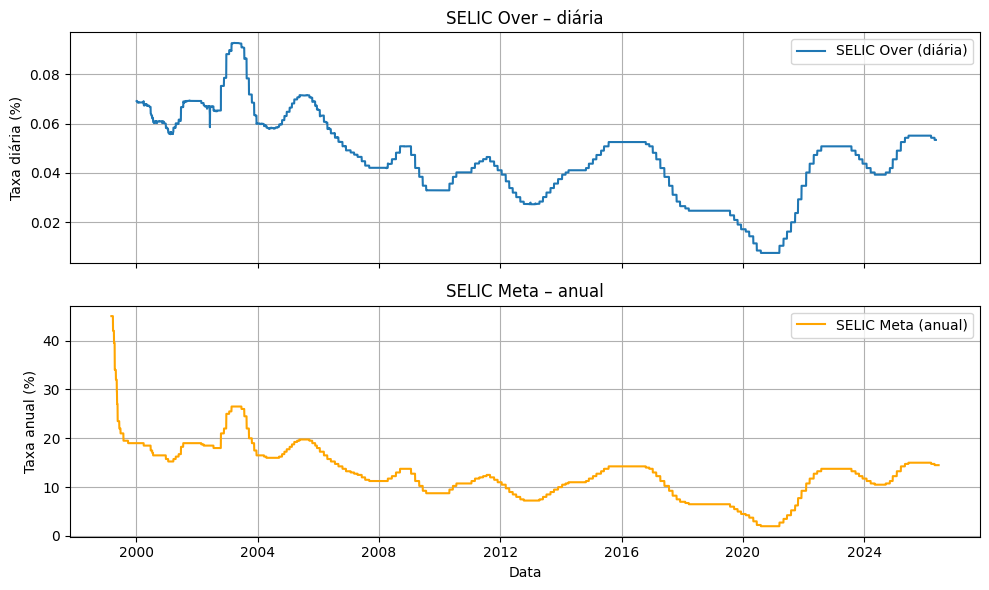

In [175]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].set_title("SELIC Over – diária"); axes[0].set_ylabel("Taxa diária (%)")
axes[0].plot(selic_over["date"], selic_over["value"], label="SELIC Over (diária)")
axes[0].grid(True); axes[0].legend()

axes[1].set_title("SELIC Meta – anual"); axes[1].set_xlabel("Data"); axes[1].set_ylabel("Taxa anual (%)")
axes[1].plot(selic_meta["date"], selic_meta["value"], color="orange", label="SELIC Meta (anual)")
axes[1].grid(True); axes[1].legend()

plt.tight_layout()
plt.show()

- **<u> Indíce no mês (15º dia) </u>**

In [76]:
# cria coluna com o dia do mês
selic_over["day"] = selic_over["date"].dt.day
# seleciona o dia mais próximo do dia 15 em cada mês
selic_over_15 = (selic_over.loc[ selic_over.groupby([selic_over["date"].dt.year, selic_over["date"].dt.month])["day"]
                                .apply(lambda x: (x - 15).abs().idxmin())]
                .sort_values("date"))

selic_meta["day"] = selic_meta["date"].dt.day
selic_meta_15 = (selic_meta.loc[ selic_meta.groupby([selic_meta["date"].dt.year, selic_meta["date"].dt.month])["day"]
                                .apply(lambda x: (x - 15).abs().idxmin())]
                .sort_values("date"))

hoje = pd.Timestamp.today()
selic_meta_15 = selic_meta_15[selic_meta_15["date"] < hoje]

print("Selic Over 15 (15º dia):")
print(selic_over_15[["date", "value", "day"]].tail(3))
print("\nSelic Meta 15 (15º dia):")
print(selic_meta_15[["date", "value", "day"]].tail(3))


Selic Over 15 (15º dia):
         date    value  day
41 2026-03-16 0.055131   16
20 2026-04-15 0.054266   15
0  2026-05-15 0.053400   15

Selic Meta 15 (15º dia):
         date     value  day
94 2026-03-15 15.000000   15
63 2026-04-15 14.750000   15
33 2026-05-15 14.500000   15


<br>

---

<a id="ipca"></a>
[↑ Índice](#indice)
## 1. IPCA

- **<u> Executar pipeline </u>**

In [3]:
run_ipca()

2026-07-15 19:06:41,281 | INFO | src.api.sidra_client | Consultando SIDRA: tabela=1737 | → variavel=63 | periodo=all
2026-07-15 19:06:42,089 | INFO | src.api.sidra_client | Pipeline para conversão de valores concluído com sucesso.
2026-07-15 19:06:42,091 | INFO | src.api.sidra_client | Consultando SIDRA: tabela=1737 | → variavel=2266 | periodo=all
2026-07-15 19:06:43,163 | INFO | src.api.sidra_client | Pipeline para conversão de valores concluído com sucesso.
2026-07-15 19:06:43,165 | INFO | src.api.sidra_client | Consultando SIDRA: tabela=1737 | → variavel=69 | periodo=all
2026-07-15 19:06:43,953 | INFO | src.api.sidra_client | Pipeline para conversão de valores concluído com sucesso.
2026-07-15 19:06:43,955 | INFO | src.api.sidra_client | Consultando SIDRA: tabela=1737 | → variavel=2265 | periodo=all
2026-07-15 19:06:44,831 | INFO | src.api.sidra_client | Pipeline para conversão de valores concluído com sucesso.


Tabela bcb.ipca atualizada com sucesso!


- **<u> Últimos valores </u>**

In [4]:
query_real = """
    select *
    from bcb.ipca
    where date >= '1996-01-01'
    order by date;
"""
df_real = pd.read_sql(query_real, engine)

df = pd.read_sql("select * from bcb.ipca order by date desc", engine)
df.head()

,date,indice,nIndice,acumulado,acumulado12m
0,2026-06-01,0.160000,7652.370000,3.360000,4.640000
1,2026-05-01,0.580000,7640.150000,3.200000,4.720000
2,2026-04-01,0.670000,7596.090000,2.600000,4.390000
3,2026-03-01,0.880000,7545.530000,1.920000,4.140000
4,2026-02-01,0.700000,7479.710000,1.030000,3.810000


- **<u> Gráfico de variação mensal e acumulado 12m </u>**

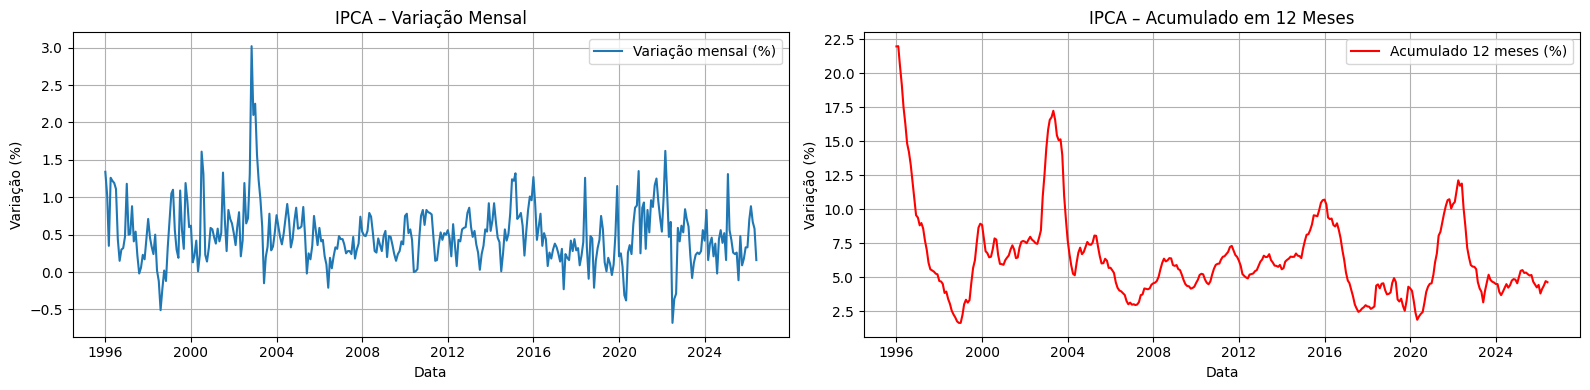

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharex=False)
# --- Gráfico 1: Variação mensal ---
axes[0].set_title("IPCA – Variação Mensal"); axes[0].set_xlabel("Data"); axes[0].set_ylabel("Variação (%)")
axes[0].plot(df_real["date"], df_real["indice"], label="Variação mensal (%)")
axes[0].grid(True)
axes[0].legend()
# --- Gráfico 2: Acumulado 12 meses ---
axes[1].set_title("IPCA – Acumulado em 12 Meses"); axes[1].set_xlabel("Data"); axes[1].set_ylabel("Variação (%)")
axes[1].plot(df_real["date"], df_real["acumulado12m"], label="Acumulado 12 meses (%)", color="red")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

- **<u> Heatmap dos últimos 24 meses </u>**

In [6]:
df_real["date"] = df_real["date"].dt.date

In [7]:
df_hm = df_real.set_index("date").tail(24)
df_hm.head()

,indice,nIndice,acumulado,acumulado12m
date,,,,
2024-07-01,0.380000,6967.890000,2.870000,4.500000
2024-08-01,-0.020000,6966.500000,2.850000,4.240000
2024-09-01,0.440000,6997.150000,3.310000,4.420000
2024-10-01,0.560000,7036.330000,3.880000,4.760000
2024-11-01,0.390000,7063.770000,4.290000,4.870000


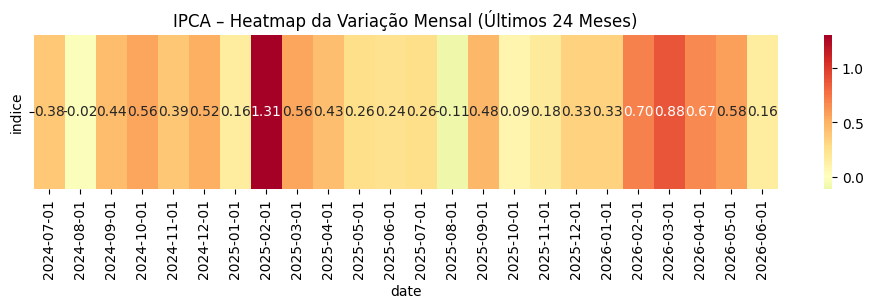

In [8]:
df_hm = df_real.set_index("date").tail(24)
plt.figure(figsize=(12, 2))
sns.heatmap(df_hm[["indice"]].T, cmap="RdYlGn_r", center=0, annot=True, fmt=".2f")
plt.title("IPCA – Heatmap da Variação Mensal (Últimos 24 Meses)")
plt.show()

- **<u> Média móvel de 12 meses da variação mensal </u>**

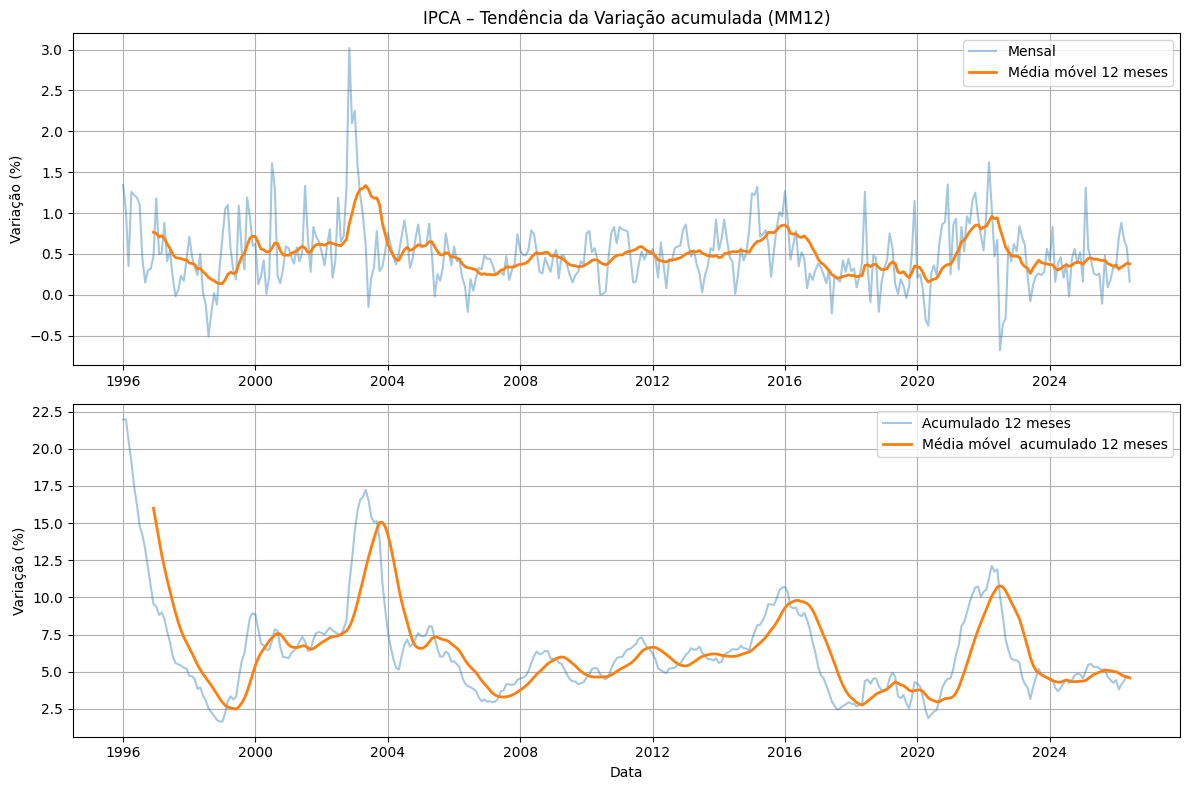

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=False)
# --- Gráfico 1: Variação mensal ---
df_real["m12"] = df_real["indice"].rolling(12).mean()
axes[0].set_title("IPCA – Tendência da Variação acumulada (MM12)"); axes[0].set_ylabel("Variação (%)")
axes[0].plot(df_real["date"], df_real["indice"], alpha=0.4, label="Mensal")
axes[0].plot(df_real["date"], df_real["m12"], linewidth=2, label="Média móvel 12 meses")
axes[0].grid(True)
axes[0].legend()
# --- Gráfico 2: Acumulado 12 meses ---
df_real["mm12"] = df_real["acumulado12m"].rolling(12).mean()
axes[1].set_xlabel("Data"); axes[1].set_ylabel("Variação (%)")
axes[1].plot(df_real["date"], df_real["acumulado12m"], alpha=0.4, label="Acumulado 12 meses")
axes[1].plot(df_real["date"], df_real["mm12"], linewidth=2, label="Média móvel  acumulado 12 meses")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

<br>

---

<a id="ipcagrupos"></a>
[↑ Índice](#indice)
## 1. IPCA Grupos

- **<u> Executar pipeline </u>**

In [3]:
run_ipca_grupos()

2026-05-18 12:06:55,581 | INFO | src.api.sidra_client | Consultando SIDRA: tabela=7060 | → variavel=63 | periodo=all
2026-05-18 12:06:57,140 | INFO | src.api.sidra_client | Pipeline para conversão de valores concluído com sucesso.
2026-05-18 12:06:57,161 | INFO | src.api.sidra_client | Consultando SIDRA: tabela=7060 | → variavel=66 | periodo=all
2026-05-18 12:07:00,842 | INFO | src.api.sidra_client | Pipeline para conversão de valores concluído com sucesso.


Tabela bcb.ipca_grupos atualizada com sucesso!


- **<u> Últimos valores por peso </u>**

In [10]:
query_grupos = """
    select *
    from bcb.ipca_grupos
    order by date asc, indice desc, category;
"""
df_grupos = pd.read_sql(query_grupos, engine)
df_grupos.tail(9)

,date,indice,peso,category,category_name
693,2026-06-01,0.630000,15.291500,2,Habitação
694,2026-06-01,0.250000,10.218400,7,Despesas pessoais
695,2026-06-01,0.230000,3.448000,3,Artigos de residência
696,2026-06-01,0.230000,13.707800,6,Saúde e cuidados pessoais
697,2026-06-01,0.190000,4.501500,9,Comunicação
698,2026-06-01,0.170000,4.628700,4,Vestuário
699,2026-06-01,0.170000,20.273100,5,Transportes
700,2026-06-01,-0.020000,6.178000,8,Educação
701,2026-06-01,-0.240000,21.753000,1,Alimentação e bebidas


- **<u> Maior infação dos grupos no mês </u>**

In [11]:
ultimo_mes = df_grupos["date"].max()
top4 = df_grupos[df_grupos["date"] == ultimo_mes].sort_values("indice", ascending=False).head(4)

def preparar_grupo(df, categoria, data_min="2025-04-01"):
    g = df[df["category"] == categoria].copy()
    g["ac12"] = g["indice"].rolling(3).mean()
    g = g[g["date"] >= data_min]
    return g

grupos_plot = []
for cat in top4["category"]:
    df_g = preparar_grupo(df_grupos, cat)
    grupos_plot.append((f"Grupo {cat}", df_g))

nomes = {
    "1": "Alimentação e bebidas",
    "2": "Habitação",
    "3": "Artigos de residência",
    "4": "Vestuário",
    "5": "Transportes",
    "6": "Saúde e cuidados pessoais",
    "7": "Despesas pessoais",
    "8": "Educação",
    "9": "Comunicação"
}

grupos_plot = [(nomes[cat], preparar_grupo(df_grupos, cat)) for cat in top4["category"]]
#for nome, df in grupos_plot:
#    df["date_fmt"] = df["date"].dt.strftime("%m/%Y")


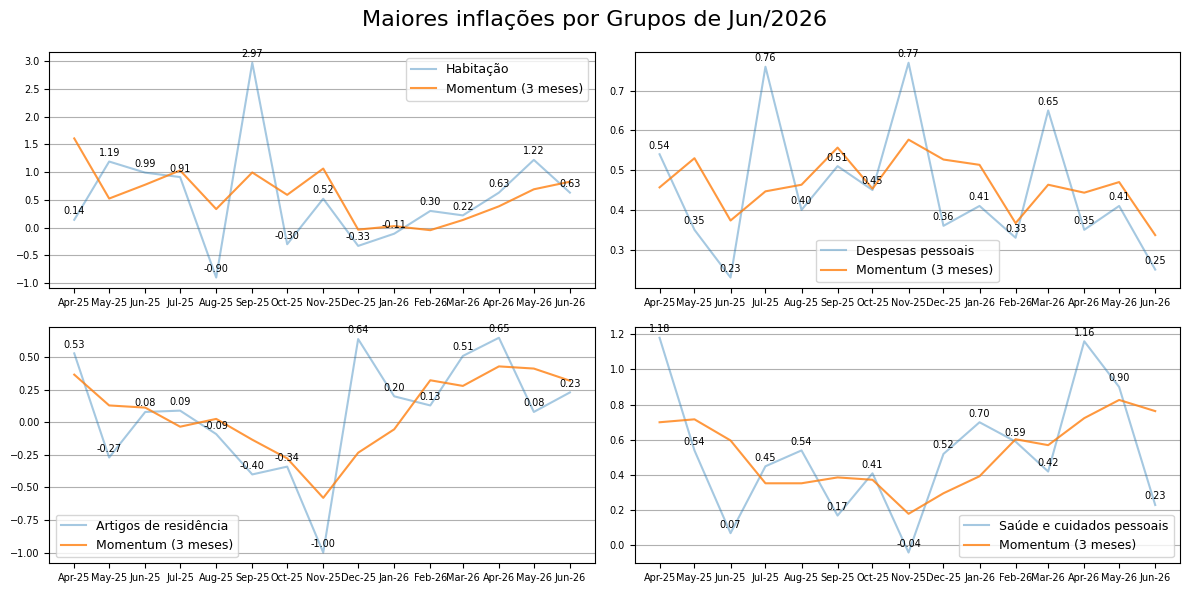

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(12, 6))

# título geral do quadro
titulo_quadro = f"Maiores inflações por Grupos de {ultimo_mes.strftime('%b/%Y')}"
fig.suptitle(titulo_quadro, fontsize=16)

for (titulo, df), eixo in zip(grupos_plot, ax.ravel()):
#    eixo.set_title(f"IPCA Grupos | {titulo}")
    eixo.plot(df["date"], df["indice"], alpha=0.4, label={titulo})
    eixo.plot(df["date"], df["ac12"], alpha=0.8, label="Momentum (3 meses)")

   # anotar valores nos pontos
    for x, y in zip(df["date"], df["indice"]):
        eixo.annotate(
            f"{y:.2f}",
            (x, y),
            textcoords="offset points",
            xytext=(0, 4),   # deslocamento vertical
            ha="center",
            fontsize=7
        )

    # Formatação data no eixo x
    eixo.grid(axis='y')
    eixo.legend(fontsize=9)
    eixo.tick_params(axis='y', labelsize=7)
    eixo.tick_params(axis='x', rotation=0, labelsize=7)
    eixo.xaxis.set_major_locator(mdates.MonthLocator())
    eixo.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y'))


plt.tight_layout()
plt.show()

2026-07-15 19:07:30,392 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-07-15 19:07:30,406 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


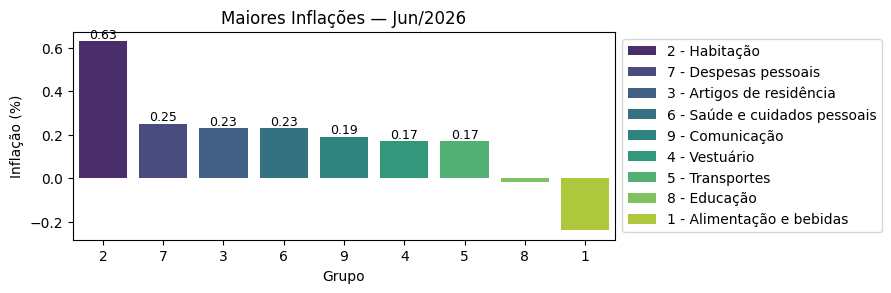

In [13]:
df_ult = df_grupos[df_grupos["date"] == ultimo_mes]
df_ult["category_idname"] = df_ult["category"].astype(str) + " - " + df_ult["category_name"]

plt.figure(figsize=(7, 2.7))
i = sns.barplot(x="category", y="indice", hue="category_idname", data=df_ult, palette="viridis")
plt.title(f"Maiores Inflações — {ultimo_mes.strftime('%b/%Y')}")
plt.xlabel("Grupo"); plt.ylabel("Inflação (%)")
plt.legend(bbox_to_anchor=(1, 1), loc="upper left")

# adicionar valores acima das barras
for p in i.patches:
    valor = p.get_height()
    if valor > 0:
        i.annotate(f"{valor:.2f}", (p.get_x() + p.get_width() / 2, valor), ha="center",va="bottom",fontsize=9)

plt.show()

- **<u> Heatmap dos últimos 12 meses </u>**

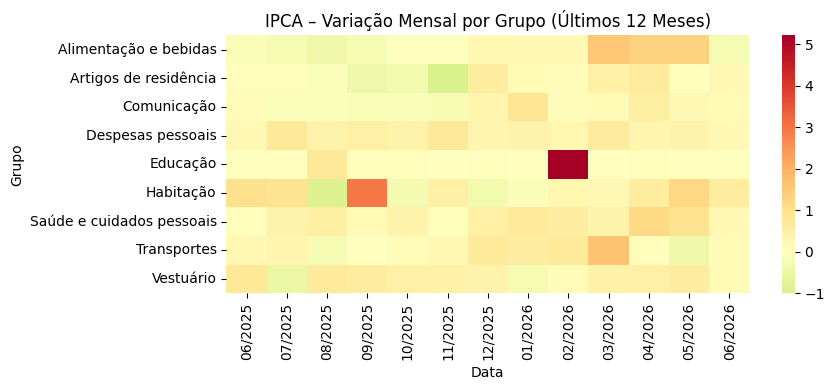

In [14]:
dfgrupos = df_grupos[df_grupos["date"] >= df_grupos["date"].max() - pd.offsets.DateOffset(months=12)]

pivot_g = dfgrupos.pivot_table(index="category_name", columns="date", values="indice")
pivot_g.columns = pivot_g.columns.strftime("%m/%Y")

plt.figure(figsize=(9, max(4, len(pivot_g) * 0.25)))
sns.heatmap(pivot_g, cmap="RdYlGn_r", center=0, annot=False)
plt.title("IPCA – Variação Mensal por Grupo (Últimos 12 Meses)")
plt.xlabel("Data"); plt.ylabel("Grupo"); plt.tight_layout()
plt.show()

<br>

---

<a id="ipcasubgrupos"></a>
[↑ Índice](#indice)
## 1. IPCA Sub-Grupos

- **<u> Executar pipeline </u>**

In [3]:
run_ipca_subgrupos()

2026-05-18 18:28:42,136 | INFO | src.api.sidra_client | Consultando SIDRA: tabela=7060 | → variavel=63 | periodo=all
2026-05-18 18:28:43,912 | INFO | src.api.sidra_client | Pipeline para conversão de valores concluído com sucesso.
2026-05-18 18:28:43,930 | INFO | src.api.sidra_client | Consultando SIDRA: tabela=7060 | → variavel=66 | periodo=all
2026-05-18 18:28:45,632 | INFO | src.api.sidra_client | Pipeline para conversão de valores concluído com sucesso.


Tabela bcb.ipca_subgrupos atualizada com sucesso!


- **<u> Últimos valores </u>**

In [15]:
query_subgrupos = """
    select *
    from bcb.ipca_subgrupos
    order by date, indice desc;
"""
df_subgrupos = pd.read_sql(query_subgrupos, engine)
df_subgrupos.tail(19)

,date,indice,peso,category,category_name
1463,2026-06-01,1.120000,5.522700,22,Combustíveis e energia
1464,2026-06-01,0.620000,1.213600,42,Calçados e acessórios
1465,2026-06-01,0.560000,0.344300,33,Consertos e manutenção
1466,2026-06-01,0.410000,6.316000,71,Serviços pessoais
1467,2026-06-01,0.390000,5.919700,62,Serviços de saúde
1468,2026-06-01,0.360000,9.768800,21,Encargos e manutenção
1469,2026-06-01,0.340000,4.070300,63,Cuidados pessoais
1470,2026-06-01,0.300000,0.050500,44,Tecidos e armarinho
1471,2026-06-01,0.250000,1.382100,32,Aparelhos eletroeletrônicos
1472,2026-06-01,0.190000,4.501500,91,Comunicação


- **<u> Maior infação de subGrupos no mês </u>**

In [ ]:
ultimo_mes = df_subgrupos["date"].max()
top6 = df_subgrupos[df_subgrupos["date"] == ultimo_mes].sort_values("indice", ascending=False).head(6)

def preparar_subgrupo(df, categoria, data_min="2025-04-01"):
    sg = df[df["category"] == categoria].copy()
    sg["ac12"] = sg["indice"].rolling(3).mean()
    sg = sg[sg["date"] >= data_min]
    return sg

nomes = dict(
    zip(
        df_categories["idSubGrupos"].astype(str),
        df_categories["subGrupos"]
    )
)

subgrupos_plot = [(nomes[str(cat)], preparar_subgrupo(df_subgrupos, cat)) for cat in top6["category"]]
#for nome, df in subgrupos_plot:
#    df["date_fmt"] = df["date"].dt.strftime("%m/%Y")


In [ ]:
fig, ax = plt.subplots(3, 2, figsize=(12, 9))
    
# título geral do quadro
titulo_quadro = f"Maiores inflações SubGrupos de {ultimo_mes.strftime('%b/%Y')}"
fig.suptitle(titulo_quadro, fontsize=16)

for (titulo, df), eixo in zip(subgrupos_plot, ax.ravel()):
#    eixo.set_title(f"IPCA Subgrupos | {titulo}")
    eixo.plot(df["date"], df["indice"], alpha=0.4, label={titulo})
    eixo.plot(df["date"], df["ac12"], alpha=0.8, label="Momentum (3 meses)")

   # anotar valores nos pontos
    for x, y in zip(df["date"], df["indice"]):
        eixo.annotate(
            f"{y:.2f}",
            (x, y),
            textcoords="offset points",
            xytext=(0, 4),   # deslocamento vertical
            ha="center",
            fontsize=7
        )

    # Formatação data no eixo x
    eixo.grid(axis='y')
    eixo.legend(fontsize=9)
    eixo.tick_params(axis='y', labelsize=7)
    eixo.tick_params(axis='x', rotation=0, labelsize=7)
    eixo.xaxis.set_major_locator(mdates.MonthLocator())
    eixo.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y'))

plt.tight_layout()
plt.show()

2026-07-15 19:08:31,494 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-07-15 19:08:31,508 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


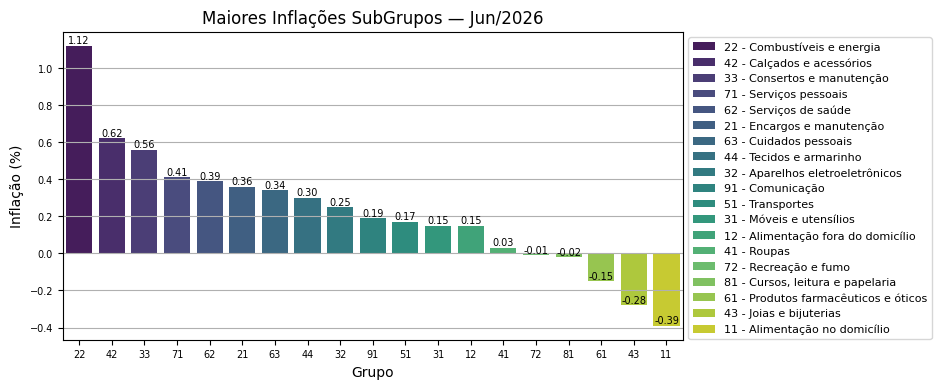

In [18]:
df_ult = df_subgrupos[df_subgrupos["date"] == ultimo_mes]
df_ult["category_idname"] = df_ult["category"].astype(str) + " - " + df_ult["category_name"]

plt.figure(figsize=(8, 4))
i = sns.barplot(x="category", y="indice", hue="category_idname", data=df_ult, palette="viridis")
plt.title(f"Maiores Inflações SubGrupos — {ultimo_mes.strftime('%b/%Y')}")
plt.xlabel("Grupo"); plt.ylabel("Inflação (%)")
plt.legend(bbox_to_anchor=(1, 1), loc="upper left", fontsize=8)
# Formatação data no eixo x
plt.grid(axis='y')
plt.tick_params(axis='y', labelsize=7)
plt.tick_params(axis='x', labelsize=7)


# adicionar valores acima das barras
for p in i.patches:
    valor = p.get_height()
    if valor != 0:
        i.annotate(f"{valor:.2f}", (p.get_x() + p.get_width() / 2, valor), ha="center",va="bottom",fontsize=7)

plt.show()

- **<u> Heatmap dos últimos 12 meses </u>**

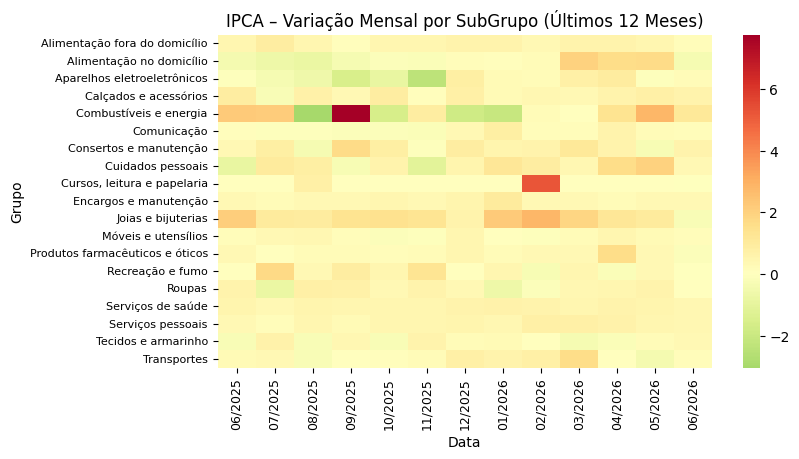

In [19]:
dfsubgrupos = df_subgrupos[df_subgrupos["date"] >= df_subgrupos["date"].max() - pd.offsets.DateOffset(months=12)]

pivot_g = dfsubgrupos.pivot_table(index="category_name", columns="date", values="indice")
pivot_g.columns = pivot_g.columns.strftime("%m/%Y")

plt.figure(figsize=(9, max(4, len(pivot_g) * 0.25)))
sns.heatmap(pivot_g, cmap="RdYlGn_r", center=0, annot=False)
plt.title("IPCA – Variação Mensal por SubGrupo (Últimos 12 Meses)")
plt.xlabel("Data"); plt.ylabel("Grupo"); plt.tight_layout()
plt.tick_params(axis='y', labelsize=8)
plt.tick_params(axis='x', labelsize=9)

plt.show()

<br>

---

<a id="ipcaitens"></a>
[↑ Índice](#indice)
## 1. IPCA Itens

- **<u> Executar pipeline </u>**

In [21]:
run_ipca_itens()

2026-07-15 19:09:11,469 | INFO | src.api.sidra_client | Consultando SIDRA: tabela=7060 | → variavel=63 | periodo=all
2026-07-15 19:09:16,266 | INFO | src.api.sidra_client | Pipeline para conversão de valores concluído com sucesso.
2026-07-15 19:09:16,281 | INFO | src.api.sidra_client | Consultando SIDRA: tabela=7060 | → variavel=66 | periodo=all
2026-07-15 19:09:19,395 | INFO | src.api.sidra_client | Pipeline para conversão de valores concluído com sucesso.


Tabela bcb.ipca_itens atualizada com sucesso!


- **<u> Últimos valores </u>**

In [20]:
query_itens = """
    select *
    from bcb.ipca_itens
    order by date, indice desc;
"""

df_itens = pd.read_sql(query_itens, engine)
df_itens.tail()

,date,indice,peso,category,category_name
3871,2026-04-01,-0.310000,1.967300,1114,Bebidas e infusões
3872,2026-04-01,-0.490000,0.790000,1104,Açúcares e derivados
3873,2026-04-01,-0.530000,0.239700,6102,Produtos óticos
3874,2026-04-01,-0.560000,1.254600,1110,Aves e ovos
3875,2026-04-01,-4.000000,3.233900,5101,Transporte público


- **<u> Maior infação de Itens no mês </u>**

In [27]:
ultimo_mes = df_itens["date"].max()
top6 = df_itens[df_itens["date"] == ultimo_mes].sort_values("indice", ascending=False).head(6)

def preparar_itens(df, categoria, data_min="2025-04-01"):
    i = df[df["category"] == categoria].copy()
    i["ac12"] = i["indice"].rolling(3).mean()
    i = i[i["date"] >= data_min]
    return i

nomes = dict(
    zip(
        df_categories["idItens"].astype(str),
        df_categories["itens"]
    )
)

itens_plot = [(nomes[str(cat)], preparar_itens(df_itens, cat)) for cat in top6["category"]]

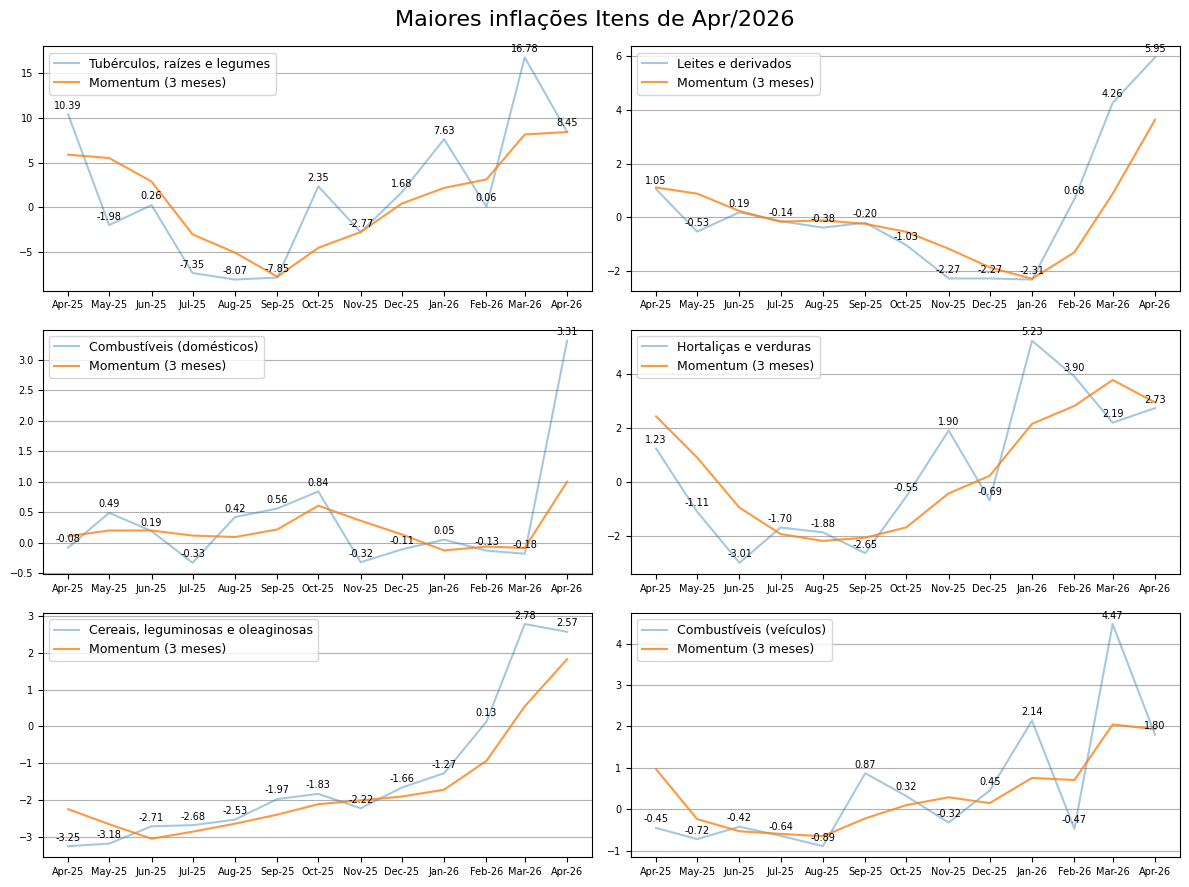

In [26]:
fig, ax = plt.subplots(3, 2, figsize=(12, 9))
    
# título geral do quadro
titulo_quadro = f"Maiores inflações Itens de {ultimo_mes.strftime('%b/%Y')}"
fig.suptitle(titulo_quadro, fontsize=16)

for (titulo, df), eixo in zip(itens_plot, ax.ravel()):
#    eixo.set_title(f"IPCA Itens | {titulo}")
    eixo.plot(df["date"], df["indice"], alpha=0.4, label={titulo})
    eixo.plot(df["date"], df["ac12"], alpha=0.8, label="Momentum (3 meses)")

   # anotar valores nos pontos
    for x, y in zip(df["date"], df["indice"]):
        eixo.annotate(
            f"{y:.2f}",
            (x, y),
            textcoords="offset points",
            xytext=(0, 4),   # deslocamento vertical
            ha="center",
            fontsize=7
        )

    # Formatação data no eixo x
    eixo.grid(axis='y')
    eixo.legend(fontsize=9)
    eixo.tick_params(axis='y', labelsize=7)
    eixo.tick_params(axis='x', rotation=0, labelsize=7)
    eixo.xaxis.set_major_locator(mdates.MonthLocator())
    eixo.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y'))

plt.tight_layout()
plt.show()

2026-05-18 21:27:37,922 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-05-18 21:27:37,935 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


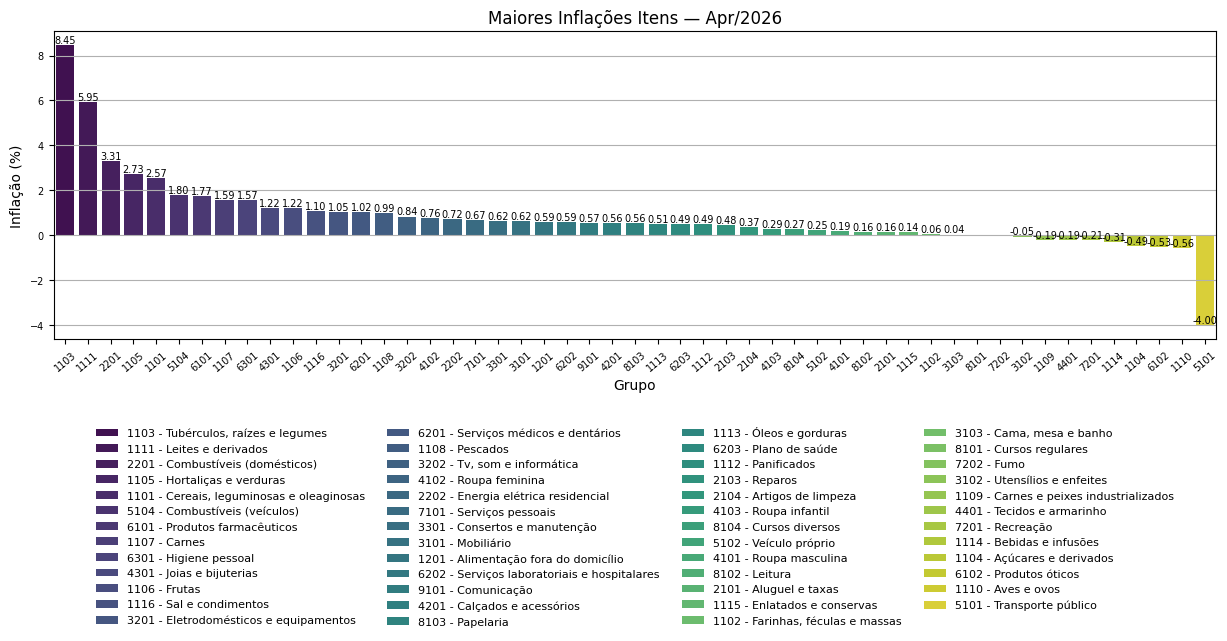

In [74]:
df_ult = df_itens[df_itens["date"] == ultimo_mes]
df_ult["category_idname"] = df_ult["category"].astype(str) + " - " + df_ult["category_name"]

plt.figure(figsize=(15, 4))
i = sns.barplot(x="category", y="indice", hue="category_idname", data=df_ult, palette="viridis")
plt.title(f"Maiores Inflações Itens — {ultimo_mes.strftime('%b/%Y')}")
plt.xlabel("Grupo"); plt.ylabel("Inflação (%)")
plt.legend(
    bbox_to_anchor=(0.5, -0.25),   # abaixo do gráfico
    loc="upper center",
    ncol=4,                        # número de colunas (ajuste como quiser)
    fontsize=8,
    frameon=False
)# Formatação data no eixo x
plt.grid(axis='y')
plt.tick_params(axis='y', labelsize=7)
plt.tick_params(axis='x', rotation=40 , labelsize=7)


# adicionar valores acima das barras
for p in i.patches:
    valor = p.get_height()
    if valor != 0:
        i.annotate(f"{valor:.2f}", (p.get_x() + p.get_width() / 2, valor), ha="center",va="bottom",fontsize=7)

plt.show()

<br>

---

<a id="ipcasubitens"></a>
[↑ Índice](#indice)
## 1. IPCA Sub-Itens

- **<u> Executar pipeline </u>**

In [22]:
run_ipca_subitens()

2026-07-15 19:09:29,948 | INFO | src.api.sidra_client | Consultando SIDRA: tabela=7060 | → variavel=63 | periodo=all
2026-07-15 19:09:33,055 | INFO | src.api.sidra_client | Pipeline para conversão de valores concluído com sucesso.
2026-07-15 19:09:33,071 | INFO | src.api.sidra_client | Consultando SIDRA: tabela=7060 | → variavel=66 | periodo=all
2026-07-15 19:09:35,250 | INFO | src.api.sidra_client | Pipeline para conversão de valores concluído com sucesso.


Tabela bcb.ipca_subitens atualizada com sucesso!


- **<u> Últimos valores </u>**

In [23]:
query_ipca_subitens = """
    select *
    from bcb.ipca_subitens
    order by date, indice asc;
"""
df_subitens = pd.read_sql(query_ipca_subitens, engine)
df_subitens.tail(30)

,date,indice,peso,category,category_name
29376,2026-06-01,2.340000,0.022900,4101005,Agasalho masculino
29377,2026-06-01,2.390000,0.039300,2103041,Material hidráulico
29378,2026-06-01,2.410000,0.007700,7201067,Material de caça e pesca
29379,2026-06-01,2.410000,0.014300,3101017,Colchão
29380,2026-06-01,2.420000,0.008300,4103005,Agasalho infantil
29381,2026-06-01,2.420000,0.009900,1103020,Abobrinha
29382,2026-06-01,2.460000,0.001700,3301006,Conserto de televisor
29383,2026-06-01,2.520000,0.010600,1109023,Bacalhau
29384,2026-06-01,2.620000,0.000400,1108112,Peixe - pintado
29385,2026-06-01,2.620000,0.002700,3202008,Videogame (console)


In [24]:
unidade = df_subitens[df_subitens["category_name"].str.contains("Café moído", case=False, na=False)]
unidade.tail(20)


,date,indice,peso,category,category_name
22191,2024-11-01,2.330000,0.465300,1114022,Café moído
22603,2024-12-01,4.990000,0.474200,1114022,Café moído
22989,2025-01-01,8.560000,0.495300,1114022,Café moído
23368,2025-02-01,10.770000,0.536800,1114022,Café moído
23743,2025-03-01,8.140000,0.586900,1114022,Café moído
24115,2025-04-01,4.480000,0.631200,1114022,Café moído
24495,2025-05-01,4.590000,0.656800,1114022,Café moído
24764,2025-06-01,0.560000,0.685100,1114022,Café moído
24945,2025-07-01,-1.010000,0.687200,1114022,Café moído
25291,2025-08-01,-2.170000,0.678600,1114022,Café moído


In [38]:
ultimo_mes = df_subitens["date"].max()
top6 = df_subitens[df_subitens["date"] == ultimo_mes].sort_values("indice", ascending=False).head(6)

def preparar_itens(df, categoria, data_min="2025-04-01"):
    si = df[df["category"] == categoria].copy()
    si["ac12"] = si["indice"].rolling(3).mean()
    si = si[si["date"] >= data_min]
    return si

nomes = dict(
    zip(
        df_categories["idSubItens"].astype(str),
        df_categories["subItens"]
    )
)

itens_plot = [(nomes[str(cat)], preparar_itens(df_subitens, cat)) for cat in top6["category"]]

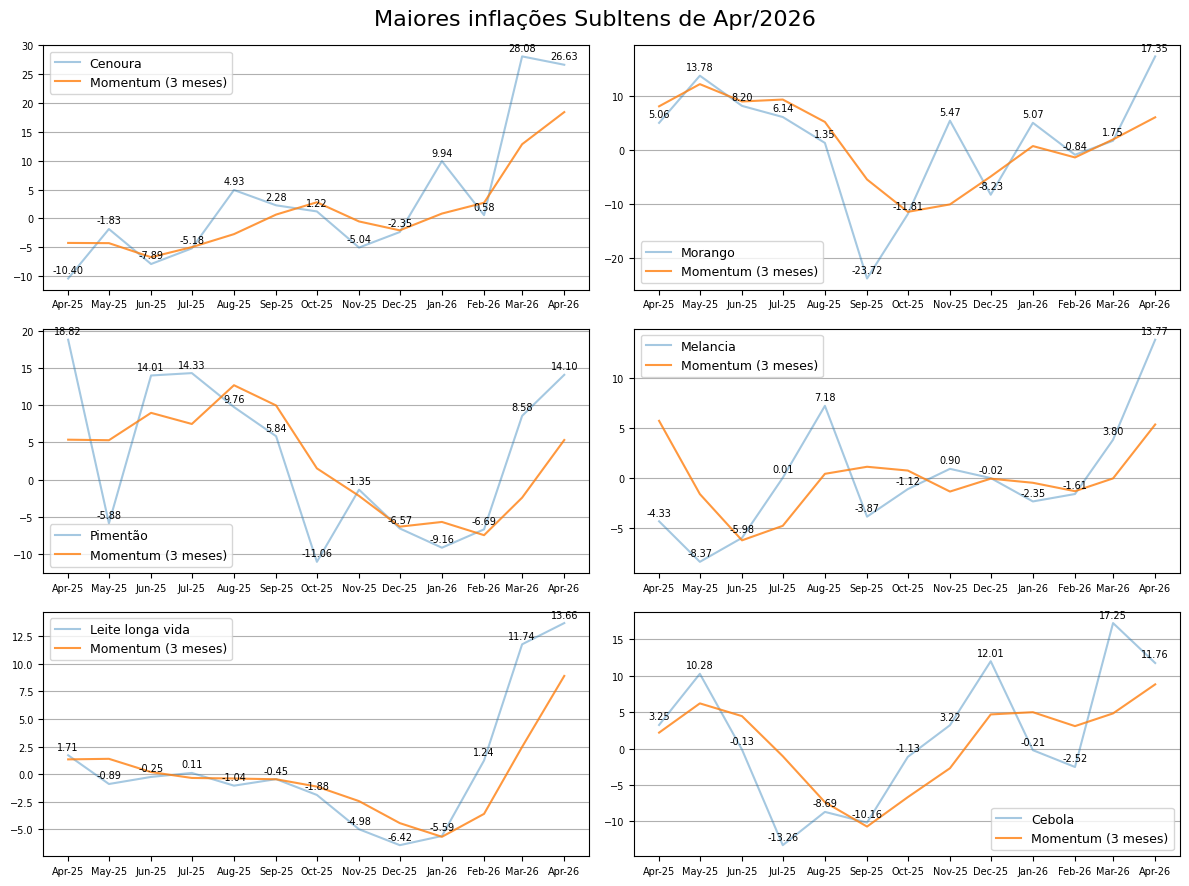

In [39]:
fig, ax = plt.subplots(3, 2, figsize=(12, 9))
    
# título geral do quadro
titulo_quadro = f"Maiores inflações SubItens de {ultimo_mes.strftime('%b/%Y')}"
fig.suptitle(titulo_quadro, fontsize=16)

for (titulo, df), eixo in zip(itens_plot, ax.ravel()):
#    eixo.set_title(f"IPCA Itens | {titulo}")
    eixo.plot(df["date"], df["indice"], alpha=0.4, label={titulo})
    eixo.plot(df["date"], df["ac12"], alpha=0.8, label="Momentum (3 meses)")

   # anotar valores nos pontos
    for x, y in zip(df["date"], df["indice"]):
        eixo.annotate(
            f"{y:.2f}",
            (x, y),
            textcoords="offset points",
            xytext=(0, 4),   # deslocamento vertical
            ha="center",
            fontsize=7
        )

    # Formatação data no eixo x
    eixo.grid(axis='y')
    eixo.legend(fontsize=9)
    eixo.tick_params(axis='y', labelsize=7)
    eixo.tick_params(axis='x', rotation=0, labelsize=7)
    eixo.xaxis.set_major_locator(mdates.MonthLocator())
    eixo.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y'))

plt.tight_layout()
plt.show()

<br>

---

<a id="view"></a>
[↑ Índice](#indice)
## load views

In [25]:
load_views()

View carregada: vw_groupsBySubItems.sql
View carregada: vw_listCategories.sql
View carregada: vw_ipca_mensal.sql
View carregada: vw_selic_over_diaria.sql
View carregada: vw_ipca_vs_selic.sql
View carregada: vw_ipca_12m.sql
View carregada: vw_selic_meta_anual.sql
View carregada: vw_selic_over_anualizada.sql
View carregada: vw_ipca_grupos_mensal.sql
View carregada: vw_ipca_itens_mensal.sql
View carregada: vw_ipca_tendencia_mm12.sql
View carregada: vw_ipca_subitens_mensal.sql
View carregada: vw_calendar.sql
View carregada: vw_ipca_subgrupos_mensal.sql
View carregada: vw_blocos_macro.sql
View carregada: vw_selic_comparacao.sql
